[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TheBestProEver/100micron-sim/blob/main/notebooks/02_momentum_conservation.ipynb)

# 02 · Momentum conservation: what the code guarantees, and why

**The question.** When two grains collide in the DOLL-E simulator, their total momentum comes out exactly as it went
in, while their kinetic energy does not. Why is that, where in the code is it guaranteed, and how would we notice if
the code got it wrong?

**After this notebook you can explain**
- how Newton's third law (equal and opposite contact forces) makes the total momentum constant, for ANY force law;
- why the time-stepping loop keeps it constant to round-off error (about 1e-16), and which line of code does it, in
  the readable core and in the full simulator;
- why kinetic energy is not conserved, how it splits into a centre-of-mass part (which cannot change) and a
  relative part (which the contact takes), and where that energy goes;
- why grains that stick move on together at the centre-of-mass velocity, also in a line of several grains;
- what a violation looks like, and how the full simulator's own checks measure momentum conservation.

**Units.** SI unless stated: momentum in kg m/s, energy in J. Plots use µs, mm/s.

In [1]:
# Make the repository's packages (dolle_core, dolle_sim, and the optional extras) importable, in Colab or from a clone.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:   # in Colab: install the repository from GitHub (takes ~30 s)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/TheBestProEver/100micron-sim.git"], check=True)
else:                               # locally: the repository folder is this folder or the one above (notebooks/)
    repo = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "dolle_core").is_dir())
    sys.path.insert(0, str(repo))
    if (repo / "extras").is_dir():  # the optional v0.6 engine (extras/dolle_extras), used by the 3-D cells
        sys.path.insert(1, str(repo / "extras"))

In [2]:
import math
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
import dolle_core as dc                      # the readable core of the DOLL-E simulator
from dolle_core import nb_collisions as nb   # short plotting and bookkeeping helpers for these notebooks
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

## 1. From Newton's third law to momentum conservation

Two grains on a line, masses $m_1$, $m_2$ [kg], velocities $v_1$, $v_2$ [m/s]. While they touch, the contact pushes
them apart with a force $F$ [N] (negative when adhesion pulls them together). Newton's third law says the force on
grain 1 is exactly minus the force on grain 2:

$$m_1\frac{dv_1}{dt} = -F, \qquad m_2\frac{dv_2}{dt} = +F .$$

Add the two equations:

$$\frac{d}{dt}\left(m_1v_1 + m_2v_2\right) = -F + F = 0 .$$

So the **total momentum** $P = m_1v_1 + m_2v_2$ [kg m/s] never changes, whatever $F$ is: the JKR force, the damping,
plastic yield all cancel in the sum. The **centre of mass** $X = (m_1x_1 + m_2x_2)/M$ with $M = m_1 + m_2$ moves at
$dX/dt = P/M = v_{cm}$, a constant velocity.

For $N$ grains, every contact force appears twice, with opposite signs, on the two grains it joins; summed over all
grains each pair cancels, so $\sum_i m_i\,dv_i/dt = 0$. Only EXTERNAL forces (a wall, gas drag, the rocket's
acceleration) can change the total momentum of the grains.

## 2. Watch it in one impact

Grain 1 (silica, radius 50 µm) at 20 mm/s runs into grain 2 at rest. The trace records both velocities after
every time step.

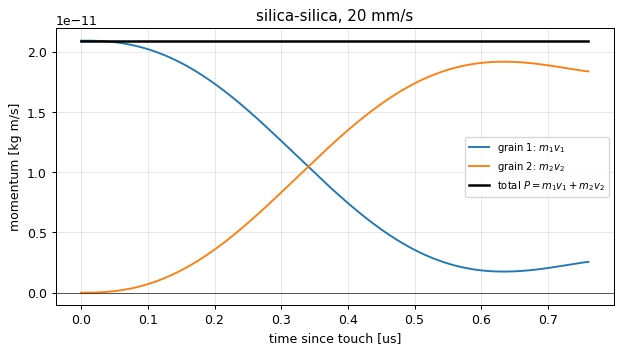

bounce, e = 0.7562; velocities after: v1 = 2.4378 mm/s, v2 = 17.5622 mm/s
total momentum before 2.0943951024e-11 kg m/s, after 2.0943951024e-11 kg m/s
largest change at any of the 340 steps, relative to m1 u1: 1.5e-15


In [3]:
r = 50e-6                                                         # grain radius [m]
res = dc.collide("silica", r, "silica", r, u1=0.020, u2=0.0)      # grain 1 at 20 mm/s onto grain 2 at rest
tr, m1, m2 = res.trace, res.pair.m1, res.pair.m2
nb.plot_momentum(tr["t"], m1 * tr["v1"], m2 * tr["v2"], title="silica-silica, 20 mm/s"); plt.show()
print(f"{res.outcome}, e = {res.e:.4f}; velocities after: v1 = {res.v1*1e3:.4f} mm/s, v2 = {res.v2*1e3:.4f} mm/s")
print(f"total momentum before {res.momentum_before:.10e} kg m/s, after {res.momentum_after:.10e} kg m/s")
print(f"largest change at any of the {len(tr['t'])} steps, relative to m1 u1: {nb.momentum_drift(res):.1e}")

**Why this happens.** Grain 1 loses momentum exactly as fast as grain 2 gains it, so the black line (the sum) is
flat while the two coloured lines swap most of their momentum. At the end grain 1 still moves forward slowly and
grain 2 moves off faster; with equal masses and restitution $e$ the final velocities are
$v_{1,2} = \frac{u_1}{2}(1 \mp e)$, here 2.44 and 17.56 mm/s. The largest change of the total at any step is
1.5e-15 of the momenta involved, about ten times the unit round-off of a 64-bit number: round-off error.

## 3. Why the CODE conserves it: the discrete version

The loop is velocity Verlet (notebook 01, section 4). Its half kick with the contact force $F^n$ at step $n$ is

$$v_1' = v_1 - \frac{\Delta t}{2}\frac{F^n}{m_1}, \qquad v_2' = v_2 + \frac{\Delta t}{2}\frac{F^n}{m_2}
\quad\Rightarrow\quad m_1v_1' + m_2v_2' = m_1v_1 + m_2v_2 - \frac{\Delta t}{2}F^n + \frac{\Delta t}{2}F^n
= m_1v_1 + m_2v_2 .$$

The drift moves positions only, and the second half kick is the same with $F^{n+1}$. So in exact arithmetic the
discrete momentum is conserved EXACTLY, for any step $\Delta t$ and any force law, provided the SAME number $F$ is
applied to both grains in the same half kick. In floating point every operation is rounded to about 1.1e-16 relative
(the unit round-off of a 64-bit IEEE 754 number, $2^{-53}$), so $P$ wanders at that level and no more. Unlike the
energy, momentum has no step-size error at all.

Here is the whole loop of `dolle_core/collide.py collide_pair`, in order: half kick, drift, new force, the same
force applied equal and opposite, half kick, then the stop tests:

In [4]:
nb.show_source(dc.collide_pair, "for _ in range(max_steps):", after=19)

--- collide.py: collide_pair
  290      for _ in range(max_steps):
  291          v1h, v2h = v1 + 0.5 * dt * acc1, v2 + 0.5 * dt * acc2          # half kick
  292          J2 += 0.5 * dt * F_tot
  293          s.delta += dt * (v1h - v2h)                                     # drift
  294          t += dt
  295          F_el = contact_force(law, s)                                    # contact law at the new overlap
  296          if F_el is None:                                                # test 2: broken -> bounce
  297              return _result(pair, s, "bounce", u1, u2, v1h, v2h, t, J2, rec)
  298          F_damp = law.c_d * math.sqrt(s.a) * (v1h - v2h)
  299          F_tot = F_el + F_damp
  300          acc1, acc2 = -F_tot / pair.m1, F_tot / pair.m2                  # equal and opposite
  301          v1, v2 = v1h + 0.5 * dt * acc1, v2h + 0.5 * dt * acc2           # half kick
  302          J2 += 0.5 * dt * F_tot
  303          if s.delta > s.delta_peak:
  304              s.de

The full simulator does the same. Its optional 3-D engine (`extras/dolle_extras/dem.py`) computes each contact's force ON GRAIN i once
(`contact_force`, output `out[0:3]`), then `compute_forces` adds it to grain i and subtracts the same numbers from
grain j; `run_steps` then applies the half kicks to every grain. The event-driven chamber model
(`dolle_sim/simulation.py`) resolves a bounce as one impulse $\pm P$ applied to the two bodies:

In [5]:
dem_py = Path(nb.__file__).resolve().parents[1] / "extras" / "dolle_extras" / "dem.py"   # optional, in extras/
if dem_py.exists():
    nb.show_source(dem_py, "F[j, 0] -= OUT[k, 0]", before=11, after=5)
    nb.show_source(dem_py, "v[i, d] += 0.5 * h * F[i, d] / m[i]")
else:
    print("extras/dolle_extras/dem.py is not in this copy (it is in a clone of the repository)")
nb.show_source(nb.simulator_file("simulation.py"), "self._apply_impulse(B, rB, P)", before=2)

--- dem.py
  443          if OUT[k, 10] == 0.0:
  444              continue
  445          i = ci[k]
  446          j = cj[k]
  447          F[i, 0] += OUT[k, 0]
  448          F[i, 1] += OUT[k, 1]
  449          F[i, 2] += OUT[k, 2]
  450          T[i, 0] += OUT[k, 3]
  451          T[i, 1] += OUT[k, 4]
  452          T[i, 2] += OUT[k, 5]
  453          if j >= 0:
  454              F[j, 0] -= OUT[k, 0]
  455              F[j, 1] -= OUT[k, 1]
  456              F[j, 2] -= OUT[k, 2]
  457              T[j, 0] += OUT[k, 6]
  458              T[j, 1] += OUT[k, 7]
  459              T[j, 2] += OUT[k, 8]
  ...
--- dem.py
  586                      v[i, d] += 0.5 * h * F[i, d] / m[i]
  ...
  599                      v[i, d] += 0.5 * h * F[i, d] / m[i]
  ...
--- simulation.py
  918              P = self._impulse(K, vrel, n, res.e_n)
  919              self._apply_impulse(A, rA, -P)
  920              self._apply_impulse(B, rB, P)
  ...


**Why this happens.** In each of the three codes the force (or impulse) is computed ONCE per contact and written
to the two grains with opposite signs, so the sum of all forces is zero by construction, not by luck. Reading the
`dem.py` lines: `OUT[k, 10] == 0` means contact `k` is not touching this step (skip it); `j >= 0` is a second
grain, while `j < 0` marks a wall face (number $-1-j$), which takes the reaction without moving. `OUT[k, 3:6]` is the
torque on grain i and `OUT[k, 6:9]` the torque on grain j: the reaction $-\mathbf F$ acting at the contact point,
$(\mathbf x_c - \mathbf x_j)\times(-\mathbf F)$, plus the rolling and twisting torques with the opposite sign to grain i's.
Added up, the torques of the pair cancel the torque $(\mathbf x_i - \mathbf x_j)\times\mathbf F$ of the force pair about any
point, so the total angular momentum is conserved too (section 7).

**Round-off, step by step.** The relative change of the total momentum at each step of the 20 mm/s impact:

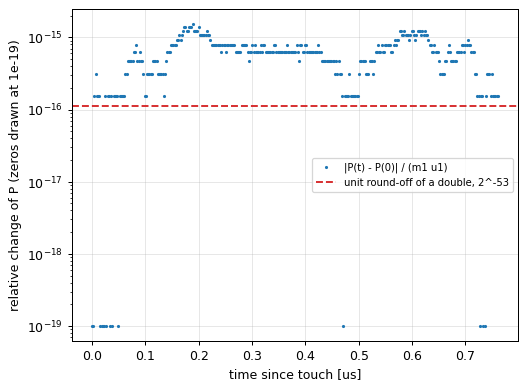

unit round-off 1.11e-16; steps with no change at all: 14 of 340; largest change 1.5e-15


In [6]:
dev = np.abs(tr["momentum"] - res.momentum_before) / (m1 * abs(res.u1))
plt.semilogy(tr["t"] * 1e6, np.maximum(dev, 1e-19), ".", ms=3, label="|P(t) - P(0)| / (m1 u1)")
plt.axhline(np.finfo(float).eps / 2, color="C3", ls="--", label="unit round-off of a double, 2^-53")
plt.xlabel("time since touch [us]"); plt.ylabel("relative change of P (zeros drawn at 1e-19)")
plt.legend(fontsize=8); plt.show()
print(f"unit round-off {np.finfo(float).eps/2:.2e}; steps with no change at all: {np.count_nonzero(dev == 0)} "
      f"of {len(dev)}; largest change {dev.max():.1e}")

**Why this happens.** At a few steps (drawn at 1e-19) the total is bit-for-bit the starting value; at the others
it differs in its last few bits, between one and about fourteen units of round-off. The difference wanders up and
down instead of growing steadily, because nothing in the loop creates momentum: each step adds a rounding error
of either sign.

## 4. Kinetic energy is NOT conserved: where it goes

Write the velocities through the centre-of-mass velocity $v_{cm} = P/M$ and the relative velocity
$v_{rel} = v_1 - v_2$: $v_1 = v_{cm} + \frac{m_2}{M}v_{rel}$, $v_2 = v_{cm} - \frac{m_1}{M}v_{rel}$. Then

$$K = \tfrac12 m_1v_1^2 + \tfrac12 m_2v_2^2 = \tfrac12 Mv_{cm}^2 + v_{cm}v_{rel}\left(\frac{m_1m_2}{M} -
\frac{m_2m_1}{M}\right) + \tfrac12\frac{m_1m_2^2 + m_2m_1^2}{M^2}v_{rel}^2 = \tfrac12 Mv_{cm}^2 + \tfrac12 m^*v_{rel}^2$$

with $m^* = m_1m_2/M$ the reduced mass (notebook 01). The first part is fixed by the momentum, so it CANNOT change.
Only the second part, the energy of the relative motion, is available to the contact. A bounce with restitution $e$
leaves $e^2$ of it, so the kinetic energy lost is $\frac12 m^*v_{in}^2(1 - e^2)$; a stick loses all of it.

In [7]:
K = lambda a, b: 0.5 * m1 * a**2 + 0.5 * m2 * b**2                # kinetic energy of the two grains [J]
E_rel = 0.5 * res.pair.m_star * res.v_in**2                        # energy of the relative motion [J]
print(f"kinetic energy before {K(res.u1, res.u2):.4e} J, after {K(res.v1, res.v2):.4e} J")
print(f"centre-of-mass part {0.5*(m1+m2)*(res.momentum_before/(m1+m2))**2:.4e} J (fixed), relative part {E_rel:.4e} J")
print(f"lost {K(res.u1, res.u2) - K(res.v1, res.v2):.4e} J;  1/2 m* v_in^2 (1 - e^2) = {E_rel*(1-res.e**2):.4e} J")
s = nb.energy_split(res)
print(f"where it went, as fractions of the relative part: damping {s['damping_loss']:.4f}, adhesion hysteresis "
      f"{s['hysteresis_loss']:.4f}, plastic {s['plastic_loss']:.4f} (left as kinetic: e^2 = {res.e**2:.4f})")

kinetic energy before 2.0944e-13 J, after 1.6461e-13 J
centre-of-mass part 1.0472e-13 J (fixed), relative part 1.0472e-13 J
lost 4.4834e-14 J;  1/2 m* v_in^2 (1 - e^2) = 4.4834e-14 J
where it went, as fractions of the relative part: damping 0.3914, adhesion hysteresis 0.0366, plastic 0.0000 (left as kinetic: e^2 = 0.5719)


**Why this happens.** Half of the incoming kinetic energy belongs to the centre-of-mass motion and stays; of the
other half, the contact keeps $1 - e^2$ = 43 %. Damping turns 39 % into heat inside the grains (internal friction),
and the adhesion hysteresis takes 3.7 %: the energy of making and breaking the contact (physically it leaves as
elastic vibrations when the contact snaps on and when the neck snaps; the model does not follow them, so this is
an interpretation). No plastic work is done at this speed. Momentum has no such
"loss channels": there is nothing it can turn into.

### A stick, and a wall

If the grains stick they must end with one common velocity, and momentum fixes which one: $v_1 = v_2 = v_{cm}$.
The code stops once it has proven the pair can never separate (notebook 01, section 8, tests 3 and 4) and then
*reports* both at $v_{cm}$, so `stuck.v1` is set, not measured. What it measured is in the trace: the last row,
when the grains are still vibrating in the contact.
On a wall the grain's own momentum is NOT conserved: the wall (fixed to the payload, effectively infinite mass) is
an external body that takes the impulse. The code books that impulse so the sum grain + wall stays constant.

In [8]:
stuck = dc.collide("silica", r, "silica", r, u1=0.005, u2=0.0)    # 5 mm/s: below the threshold
ms, last = stuck.pair, {k: v[-1] for k, v in stuck.trace.items()}          # last measured row of the trace
v_cm = stuck.momentum_before / (ms.m1 + ms.m2)
print(f"5 mm/s: {stuck.outcome}; reported v1 = v2 = {stuck.v1*1e3:.4f} mm/s = v_cm {v_cm*1e3:.4f} mm/s")
print(f"  measured at the last step: v1 = {last['v1']*1e3:.4f}, v2 = {last['v2']*1e3:.4f} mm/s (|v1 - v2| = "
      f"{abs(last['v1'] - last['v2'])*1e3:.3f} mm/s: still vibrating); (m1 v1 + m2 v2)/(m1 + m2) = "
      f"{(ms.m1*last['v1'] + ms.m2*last['v2'])/(ms.m1 + ms.m2)*1e3:.4f} mm/s; largest momentum change {nb.momentum_drift(stuck):.1e}")
wall = dc.collide("silica", r, "glass_borosilicate", None, u1=0.020)   # onto a glass wall at 20 mm/s
print(f"wall: {wall.outcome}, e = {wall.e:.4f}; grain momentum {wall.pair.m1*wall.u1:+.4e} -> "
      f"{wall.pair.m1*wall.v1:+.4e} kg m/s;  grain + wall impulse {wall.momentum_before:+.4e} -> "
      f"{wall.momentum_after:+.4e} kg m/s")

5 mm/s: stick; reported v1 = v2 = 2.5000 mm/s = v_cm 2.5000 mm/s
  measured at the last step: v1 = 0.6006, v2 = 4.3994 mm/s (|v1 - v2| = 3.799 mm/s: still vibrating); (m1 v1 + m2 v2)/(m1 + m2) = 2.5000 mm/s; largest momentum change 1.4e-15
wall: bounce, e = 0.7174; grain momentum +2.0944e-11 -> -1.5025e-11 kg m/s;  grain + wall impulse +2.0944e-11 -> +2.0944e-11 kg m/s


**Why this happens.** At the last step the grains still move at different speeds (they vibrate in the contact),
but their mass-weighted mean is already exactly $v_{cm}$ = 2.5 mm/s, half of 5 mm/s because the masses are equal:
momentum fixes it from the first step. The pair keeps only the centre-of-mass half of the kinetic energy. The grain on the wall reverses its momentum: the wall received
$(1 + e)\,m_1u_1$ and passes it on to the payload, whose mass is so large that its velocity does not change
noticeably.

## 5. Several grains on a line

`dc.line_collision` (`dolle_core/many.py`) moves N grains along a line. Every touching neighbour pair carries the
same contact law as above (JKR with its hysteresis, plus damping; no plastic yield: it refuses inputs fast enough to
yield), and every pair force is applied equal and opposite. Five grains of 50 µm radius, 0.2 µm apart: a silica
grain at 30 mm/s runs into a row of three resting grains (silica, graphite, graphite), and a fifth (silica) comes the
other way at 10 mm/s. We follow them for 300 µs.

In [9]:
mats = ["silica", "silica", "graphite", "graphite", "silica"]
radii = [r] * 5
x0 = np.arange(5) * (2 * r + 0.2e-6)                     # centres 100.2 um apart: 0.2 um gaps [m]
v0 = np.array([0.030, 0.0, 0.0, 0.0, -0.010])            # initial velocities [m/s]
line = dc.line_collision(mats, radii, x0, v0, t_end=3e-4)
P0, M = float(np.sum(line.masses * v0)), float(np.sum(line.masses))
print(f"{len(line.momentum)} steps of {line.momentum_t[0]*1e9:.3f} ns")
print(f"total momentum: start {P0:.10e}, end {line.momentum[-1]:.10e} kg m/s; largest change after any step "
      f"{np.max(np.abs(line.momentum - P0)) / np.sum(line.masses * np.abs(v0)):.1e} (relative)")
print(f"kinetic energy: start {line.kinetic[0]:.4e} J, end {line.kinetic[-1]:.4e} J")
print("final velocities [mm/s]:", np.round(line.v[-1] * 1e3, 3), "| neighbours still touching:", line.touching[-1])

161003 steps of 1.863 ns
total momentum: start 2.0943951024e-11, end 2.0943951024e-11 kg m/s; largest change after any step 5.8e-14 (relative)
kinetic energy: start 5.2360e-13 J, end 6.7747e-14 J
final velocities [mm/s]: [ 2.313  2.312  2.291  2.271 10.356] | neighbours still touching: [ True  True  True False]


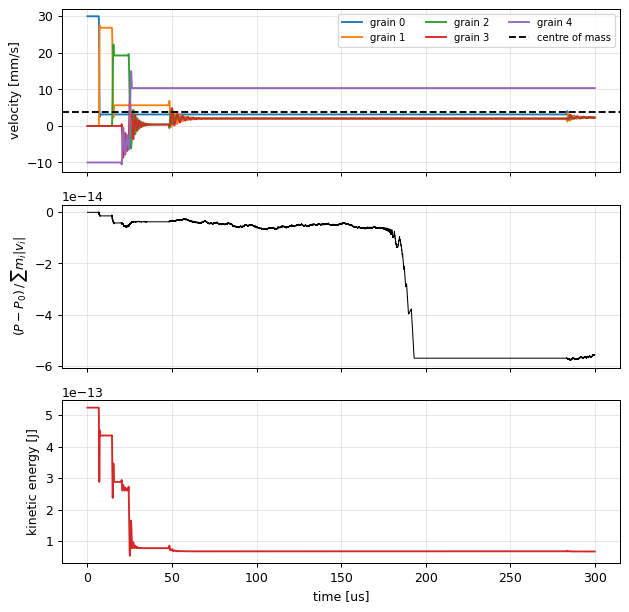

In [10]:
nb.plot_line(line); plt.show()

In [11]:
for members, v_group, spread in nb.aggregates(line):
    print(f"grains {members}: group momentum / group mass {v_group*1e3:8.4f} mm/s (spread of members {spread*1e3:.3f} mm/s)")
t_free = nb.last_contact_time(line, 3)                     # grain 4 last touched grain 3 [s]
vg = nb.group_velocity(line, [0, 1, 2, 3])[line.t > t_free]
print(f"grains 0-3 after grain 4 left (t > {t_free*1e6:.1f} us): group momentum / mass from {vg.min()*1e3:.6f} "
      f"to {vg.max()*1e3:.6f} mm/s")
X = (line.x * line.masses).sum(axis=1) / M                 # centre of mass at the recorded times [m]
print(f"centre of mass: v_cm = P/M = {P0/M*1e3:.4f} mm/s; largest |X(t) - X(0) - v_cm t| = "
      f"{np.max(np.abs(X - X[0] - P0 / M * line.t)):.1e} m")

grains [0, 1, 2, 3]: group momentum / group mass   2.2963 mm/s (spread of members 0.042 mm/s)
grains [4]: group momentum / group mass  10.3557 mm/s (spread of members 0.000 mm/s)
grains 0-3 after grain 4 left (t > 26.3 us): group momentum / mass from 2.296254 to 2.296254 mm/s
centre of mass: v_cm = P/M = 3.8462 mm/s; largest |X(t) - X(0) - v_cm t| = 2.7e-16 m


**Why this happens.** The collisions pass momentum down the row and back; the velocities jump at every contact, but
the total stays constant to round-off (middle panel: a random walk of rounding errors; the 6e-14 printed above after
161,003 steps is about what $\sqrt{N}$ steps of ~1e-16 each add up to) and the centre of mass moves in a straight
line at $v_{cm} = P/M$ (to 3e-16 m, far below the size of an atom). Here the first four grains are still touching at 300 µs and the fifth bounces away. Kinetic energy falls in
steps, one per contact (adhesion hysteresis and damping), and never rises. Once grain 4 has left, nothing outside
the group of grains 0–3 acts on it, so its momentum divided by its mass stays constant to round-off, although its
members still vibrate against each other (the spread printed above). A pair that sticks is ONE body as far as
momentum is concerned, which is how the
simulator's chamber model treats it (it merges them into a rigid aggregate that keeps their momentum and angular
momentum; PROVENANCE.md, "Sticking: rigid aggregates").

## 6. What a violation would look like

To see what the equal-and-opposite line protects us from, `nb.collide_one_sided` runs the same contact law and the
same loop, with ONE change: the force is applied to grain 1 only; grain 2 never feels the reaction (Newton's third
law switched off). This is a deliberately broken integrator, for this demonstration only.

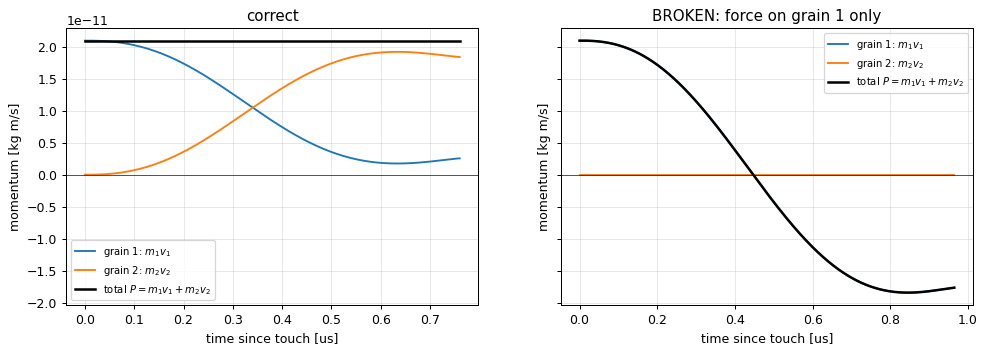

correct: P 2.0944e-11 -> 2.0944e-11 kg m/s (bounce, e = 0.756)
broken:  P 2.0944e-11 -> -1.7659e-11 kg m/s (bounce); grain 2 ends at 0.0 mm/s, grain 1 at -16.86 mm/s


In [12]:
pair = dc.make_pair("silica", r, "silica", r)
good = dc.collide_pair(pair, 0.020)                      # the real loop
bad = nb.collide_one_sided(pair, 0.020)                  # force on grain 1 only (BROKEN on purpose)
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
nb.plot_momentum(good.trace["t"], pair.m1 * good.trace["v1"], pair.m2 * good.trace["v2"], axs[0], "correct")
nb.plot_momentum(bad["t"], pair.m1 * bad["v1"], pair.m2 * bad["v2"], axs[1], "BROKEN: force on grain 1 only")
plt.show()
print(f"correct: P {good.momentum_before:.4e} -> {good.momentum_after:.4e} kg m/s ({good.outcome}, e = {good.e:.3f})")
print(f"broken:  P {bad['momentum'][0]:.4e} -> {bad['momentum'][-1]:.4e} kg m/s ({bad['outcome']}); grain 2 ends at "
      f"{bad['v2'][-1]*1e3:.1f} mm/s, grain 1 at {bad['v1'][-1]*1e3:.2f} mm/s")

**Why this happens.** Without the reaction, grain 2 never moves, so grain 1 bounces off it as if it were a fixed
wall: the total momentum flips sign (from +2.09e-11 to −1.77e-11 kg m/s) although no external force acted. The
missing momentum is exactly the impulse $\int F\,dt$ that grain 2 should have received. In a simulation of many
grains such a bug would make clusters drift or creep across the chamber on their own, and the centre of mass of an
isolated cloud would accelerate. It is not a small numerical error that a smaller time step would fix: it is a
violation at the level of the momenta themselves (here a change of 184 %), and the checks below would catch
anything far smaller.

## 7. How the full simulator checks it (CHECKS.md)

Two of the simulator's checks measure momentum conservation directly:

- **`conservation`** (`dolle_sim/verification.py check_conservation`; CHECKS.md part 1): in the chamber model, three
  graphite grains are merged into one rigid aggregate and one grain is split off again; the total linear momentum
  $P = \sum m\,v$ and angular momentum $L = \sum (L_{spin} + m\,x \times v)$ before and after must agree (criterion
  1e-6).
- **`dem_conservation`** (`extras/dolle_extras/verify_full.py check_dem_conservation`; CHECKS.md part 2): in the
  optional 3-D contact engine, an oblique impact (offset by a quarter of a diameter, 5 cm/s) of two spinning 50 µm silica grains, with no
  damping and no yield, so sliding, rolling and twisting springs all act. It measures $|\Delta P|/P$ (criterion 1e-12),
  $|\Delta L|/L$ (1e-9), and also the total energy while the contact holds (1e-6): kinetic + JKR + spring energies,
  which must stay constant when nothing dissipates.

In [13]:
from dolle_sim import verification
checks = [verification.check_conservation]
try:
    import numba                                         # the 3-D engine needs numba (desktop and Colab have it)
    from dolle_extras import verify_full                 # the optional v0.6 engine (extras/)
    checks.append(verify_full.check_dem_conservation)    # a few seconds once compiled
except ImportError:
    print("numba or the optional extras/ folder is missing: dem_conservation cannot run here "
          "(CHECKS.md part 2, row 2 lists its result)")
for check in checks:
    res7 = check()
    print(f"{res7['id']}: {res7['name']}\n  measured {res7['value']}\n  criterion {res7['criterion']}, passed: {res7['passed']}")

conservation: Momentum through sticking and fragmentation
  measured dP/P = 5.7e-17, dL/L = 1.6e-16
  criterion < 1e-6, passed: True


dem_conservation: Momentum and energy in contact dynamics
  measured |dP|/P = 5.4e-15, |dL|/L = 1.6e-14, energy varies by 6.6e-07 of the impact energy over 293 samples in contact
  criterion < 1e-12; < 1e-9; < 1e-6, passed: True


**Why this happens.** Both pass by many orders of magnitude: $\Delta P/P$ = 5.7e-17 through merging and splitting,
and 5.4e-15 through a full 3-D oblique impact with spin, i.e. round-off, as in the readable core. The angular
momentum is conserved too (1.6e-14 in the 3-D impact) because each contact force acts on both grains at the same
contact point, so its torques cancel along with its forces. The energy in the undamped 3-D impact stays constant to
6.6e-7 of the impact energy while the contact holds; that is the integrator's step error (energy, unlike momentum,
is conserved by velocity Verlet only approximately).

## What to remember

- Momentum is conserved because every contact force is applied **equal and opposite** (Newton's third law); this
  holds for any force law: JKR, damping, plastic yield.
- In the code this is exact by construction: the force is computed once per contact and added to one grain and
  subtracted from the other, in the same half kick. What remains is round-off, about 1e-16.
- Kinetic energy = centre-of-mass part (fixed by momentum) + relative part $\frac12 m^*v_{rel}^2$. The contact can
  take only the relative part: a fraction $1 - e^2$ in a bounce, all of it in a stick. It goes to heat (damping),
  elastic waves (adhesion hysteresis) and denting (plastic work).
- Grains that stick move on together at the centre-of-mass velocity; the centre of mass of an isolated group moves
  in a straight line at constant speed.
- A broken reaction force shows up as a momentum change of the order of the momenta themselves; the simulator's
  checks `conservation` and `dem_conservation` find round-off-level changes.

## Check it yourself

A graphite grain of radius 40 µm at 10 mm/s meets a silica grain of radius 50 µm coming the other way at
−4 mm/s: an approach speed of 14 mm/s. The cell first prints this pair's sticking speed with and without damping.
**Predict**: do they stick, and what is their common velocity $v_{cm} = (m_1u_1 + m_2u_2)/(m_1 + m_2)$? Then compare
with what the trace measured.

In [14]:
px = dc.make_pair("graphite", 40e-6, "silica", 50e-6)
print(f"sticking speed {dc.sticking_threshold(px)*1e3:.2f} mm/s (without damping {dc.undamped_sticking_speed(px)*1e3:.2f})")
ex = dc.collide("graphite", 40e-6, "silica", 50e-6, u1=0.010, u2=-0.004)
m_a, m_b, last = px.m1, px.m2, {k: v[-1] for k, v in ex.trace.items()}
print(f"{ex.outcome} after {len(ex.trace['t'])} steps; measured at the last step: "
      f"(m1 v1 + m2 v2)/(m1 + m2) = {(m_a*last['v1'] + m_b*last['v2'])/(m_a + m_b)*1e3:.4f} mm/s; "
      f"v_cm = {(m_a*0.010 + m_b*(-0.004))/(m_a + m_b)*1e3:.4f} mm/s; momentum change {nb.momentum_drift(ex):.1e}")

sticking speed 19.15 mm/s (without damping 9.50)
stick after 231 steps; measured at the last step: (m1 v1 + m2 v2)/(m1 + m2) = 1.0440 mm/s; v_cm = 1.0440 mm/s; momentum change 8.8e-16
